In [30]:
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import math
import plotly.io as pio
pio.renderers.default = "png"

# Baird's counterexample

## Semi-gradient Methods

In [31]:
def semiGradientMethodsBC(method, wInit, nIters, gamma=0.99, alpha=0.01):
    W = wInit.copy()
    learningCurve = np.empty((nIters, len(W)))
    VE = np.empty(nIters)

    if method == "TD" or method == "Q-learning":
        iter = 0
        currentState = np.random.choice(7)
        
        while iter < nIters:
            currentAction = np.random.choice(7) # currentAction = 0 means solid
            if currentAction == 0:
                nextState = 6
                vNextState = W[6] + 2 * W[7]
                rho = 7
            else:
                nextState = currentAction - 1
                vNextState = 2 * W[nextState] + W[7]
                rho = 0

            if method == "Q-learning":
                vNextState = max(W[6] + W[7], 2 * np.max(W[:6])) + W[7]
            
            if currentState == 6:
                vCurrentState = W[6] + 2 * W[7]
                W[6] += alpha * rho * (gamma * vNextState - vCurrentState) * 1
                W[7] += alpha * rho * (gamma * vNextState - vCurrentState) * 2

            else:
                vCurrentState = 2 * W[currentState] + W[7]
                W[currentState] += alpha * rho * (gamma * vNextState - vCurrentState) * 2
                W[7] += alpha * rho * (gamma * vNextState - vCurrentState) * 1

            learningCurve[iter] = W.copy()
            VE[iter] = (W[6] + 2 * W[7]) ** 2
            currentState = nextState
            iter += 1

    elif method == "DP" or method == "Emphatic DP":
        xFeatures = np.array([[2, 0, 0, 0, 0, 0, 0, 1],
                              [0, 2, 0, 0, 0, 0, 0, 1],
                              [0, 0, 2, 0, 0, 0, 0, 1],
                              [0, 0, 0, 2, 0, 0, 0, 1],
                              [0, 0, 0, 0, 2, 0, 0, 1],
                              [0, 0, 0, 0, 0, 2, 0, 1],
                              [0, 0, 0, 0, 0, 0, 1, 2]])
        discount = 1.
        for iter in range(nIters):
            wOld = W.copy()
            vHat = xFeatures @ wOld
            ret = (gamma * vHat[6] - vHat)
            W += alpha * np.mean(ret[:, None] * xFeatures, axis=0)
            if method == "Emphatic DP":
                W -= alpha * gamma * (1 - discount) * vHat[6] * xFeatures[6]
                discount = gamma * discount
            learningCurve[iter] = W.copy()
            VE[iter] = (W[6] + 2 * W[7]) ** 2
            
    return learningCurve, VE

In [32]:
wInit = np.array([1., 1., 1., 1., 1., 1., 10., 1.])
learningCurvesTD, VETD = semiGradientMethodsBC("TD", wInit, 1000)
learningCurvesQLearning, VEQ = semiGradientMethodsBC("Q-learning", wInit, 1000)

In [33]:
learningCurvesDP, VEDP = semiGradientMethodsBC("DP", wInit, 1000)

### SGD TD

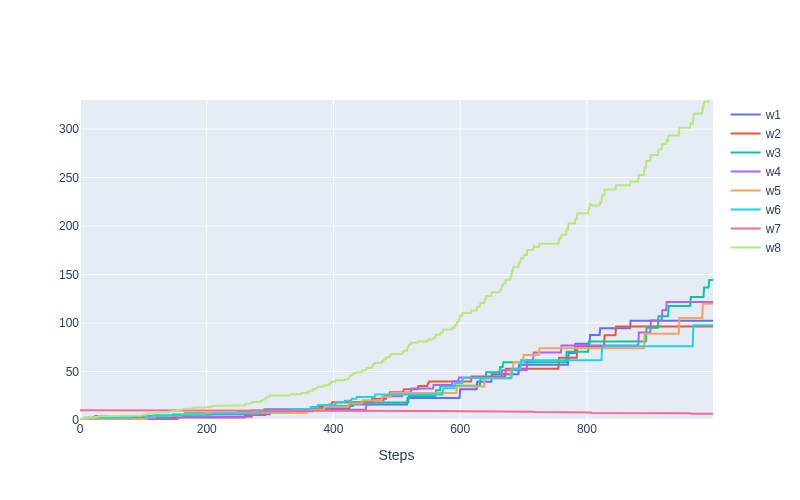

In [34]:
fig = go.Figure()
for i in range(8):
    fig.add_trace(go.Scatter(y=learningCurvesTD[:, i], name="w"+str(i+1)))
# fig.add_trace(go.Scatter(y=np.sqrt(VETD), name="sqrt(VE)"))
fig.update_layout(width=800, xaxis_title="Steps")
fig.update_yaxes(range=[0, 330])

### SGD DP

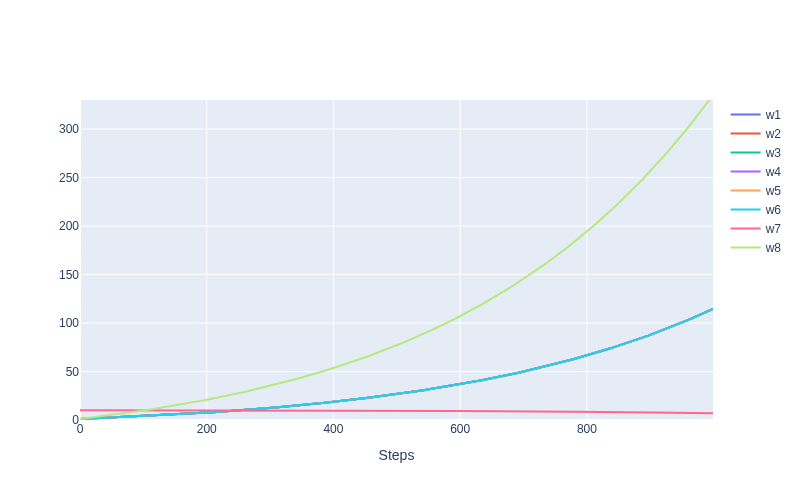

In [35]:
fig = go.Figure()
for i in range(8):
    fig.add_trace(go.Scatter(y=learningCurvesDP[:, i], name="w"+str(i+1)))
# fig.add_trace(go.Scatter(y=np.sqrt(VEDP), name="sqrt(VE)"))
fig.update_layout(width=800, xaxis_title="Steps")
fig.update_yaxes(range=[0, 330])

### SGD Q-learning

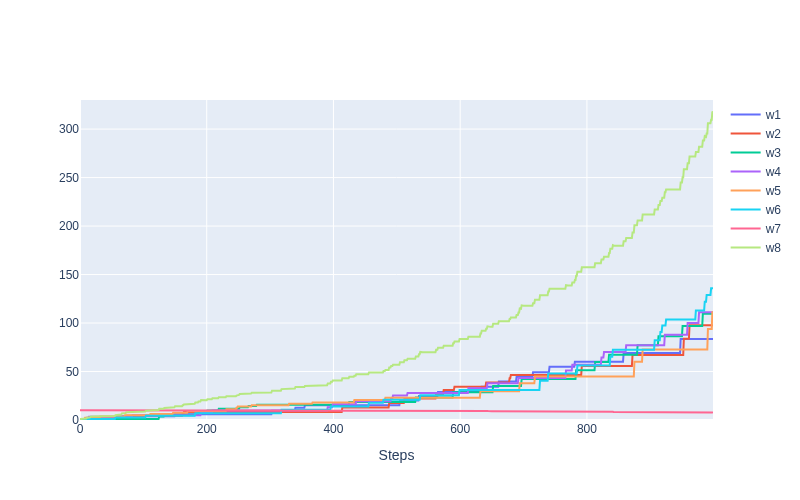

In [36]:
fig = go.Figure()
for i in range(8):
    fig.add_trace(go.Scatter(y=learningCurvesQLearning[:, i], name="w"+str(i+1)))
# fig.add_trace(go.Scatter(y=np.sqrt(VEQ), name="sqrt(VE)"))
fig.update_layout(width=800, xaxis_title="Steps")
fig.update_yaxes(range=[0, 330])

## Gradient-TD Methods

In [37]:
def temporalDifferenceGradientCorrectionBC(method, wInit, vInit, nIters, gamma=0.99, alpha=0.005, beta=0.05):
    W = wInit.copy()
    V = vInit.copy()
    learningCurve = np.empty((nIters, len(W)))
    VE = np.empty(nIters)


    if method == "TD":
        iter = 0
        currentState = np.random.choice(7)

        while iter < nIters:
            currentAction = np.random.choice(7)
            if currentAction == 0:
                nextState = 6
                approxNextState = W[6] + 2 * W[7]
                rho = 7
            else:
                nextState = currentAction - 1
                approxNextState = 2 * W[nextState] + W[7]
                rho = 0

            if currentState == 6:
                approxCurrentState = W[6] + 2 * W[7]
                delta = gamma * approxNextState - approxCurrentState
                vCurrentState = V[6] + 2 * V[7]
                update = rho * (delta - vCurrentState)
                V[6] += beta * update
                V[7] += 2 * beta * update

                W[6] += alpha * rho * delta
                W[7] += 2 * alpha * rho * delta

            else:
                approxCurrentState = 2 * W[currentState] + W[7]
                delta = gamma * approxNextState - approxCurrentState
                vCurrentState = 2 * V[currentState] + V[7]
                update = rho * (delta - vCurrentState)
                V[currentState] += 2 * beta * update
                V[7] += beta * update

                W[currentState] += 2 * alpha * rho * delta
                W[7] += alpha * rho * delta


            if nextState == 6:
                W[6] -= alpha * rho * gamma * vCurrentState
                W[7] -= 2 * alpha * rho * gamma * vCurrentState

            else:
                W[nextState] -= 2 * alpha * rho * gamma * vCurrentState
                W[7] -= alpha * rho * gamma * vCurrentState


            learningCurve[iter] = W.copy()
            VE[iter] = (W[6] + 2 * W[7]) ** 2
            currentState = nextState
            iter += 1


    elif method == "DP":
        xFeatures = np.array([[2, 0, 0, 0, 0, 0, 0, 1],
                              [0, 2, 0, 0, 0, 0, 0, 1],
                              [0, 0, 2, 0, 0, 0, 0, 1],
                              [0, 0, 0, 2, 0, 0, 0, 1],
                              [0, 0, 0, 0, 2, 0, 0, 1],
                              [0, 0, 0, 0, 0, 2, 0, 1],
                              [0, 0, 0, 0, 0, 0, 1, 2]])

        B = np.linalg.pinv(np.mean(xFeatures[:, :, None] * xFeatures[:, None, :], axis=0))

        for iter in range(nIters):
            wOld = W.copy()
            vHat = xFeatures @ wOld
            C = np.mean((gamma * vHat[6] - vHat)[:, None] * xFeatures, axis=0)
            A = np.mean((xFeatures - gamma * xFeatures[6])[:, :, None] * xFeatures[:, None, :], axis=0)
            BC = B @ C
            W += alpha * A @ BC
            learningCurve[iter] = W.copy()
            VE[iter] = (W[6] + 2 * W[7]) ** 2

    return learningCurve, VE

In [38]:
wInit = np.array([1., 1., 1., 1., 1., 1., 10., 1.])
vInit = np.array([1., 1., 1., 1., 1., 1., 1., 1.])

learningCurveTDC, VETDC = temporalDifferenceGradientCorrectionBC("TD", wInit, vInit, 1000)

### TDC

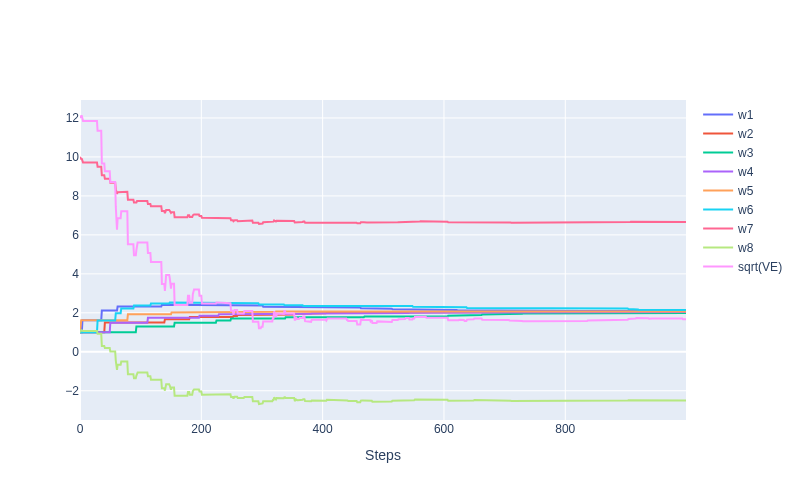

In [39]:
fig = go.Figure()
for i in range(8):
    fig.add_trace(go.Scatter(y=learningCurveTDC[:, i], name="w"+str(i+1)))
fig.add_trace(go.Scatter(y=np.sqrt(VETDC), name="sqrt(VE)"))
fig.update_layout(width=800, xaxis_title="Steps")
# fig.update_yaxes(range=[0, 330])

In [40]:
wInit = np.array([1., 1., 1., 1., 1., 1., 10., 1.])
vInit = np.array([1., 1., 1., 1., 1., 1., 1., 1.])

learningCurveExTDC, VEExTDC = temporalDifferenceGradientCorrectionBC("DP", wInit, vInit, 1000)

### Expected TDC

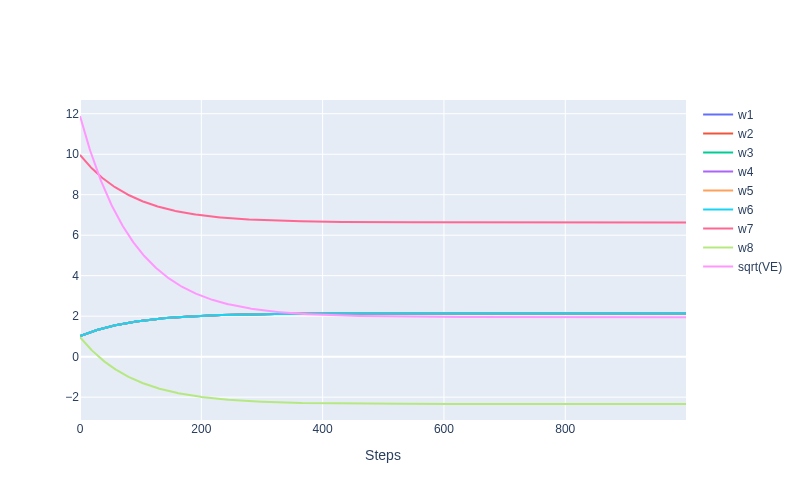

In [41]:
fig = go.Figure()
for i in range(8):
    fig.add_trace(go.Scatter(y=learningCurveExTDC[:, i], name="w"+str(i+1)))
fig.add_trace(go.Scatter(y=np.sqrt(VEExTDC), name="sqrt(VE)"))
fig.update_layout(width=800, xaxis_title="Steps")
# fig.update_yaxes(range=[0, 330])

## Emphatic TD-Methods

In [42]:
wInit = np.array([1., 1., 1., 1., 1., 1., 10., 1.])
learningCurvesEmphDP, VEEmphDP = semiGradientMethodsBC("Emphatic DP", wInit, 1000, alpha=0.03)

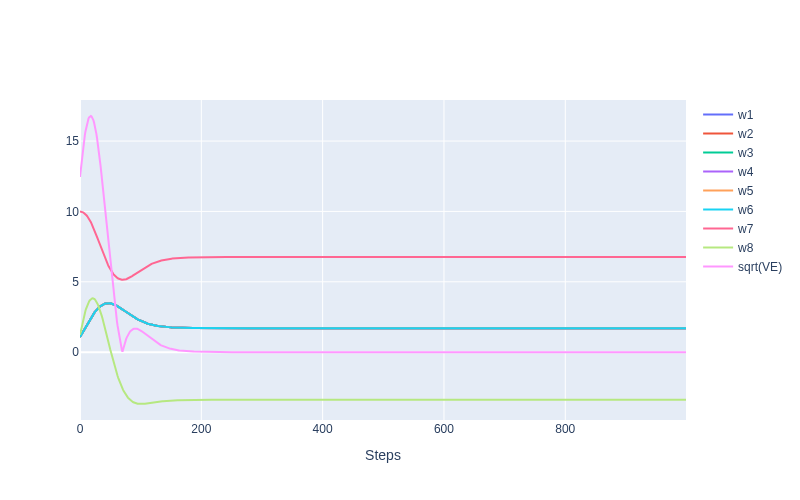

In [43]:
fig = go.Figure()
for i in range(8):
    fig.add_trace(go.Scatter(y=learningCurvesEmphDP[:, i], name="w"+str(i+1)))
fig.add_trace(go.Scatter(y=np.sqrt(VEEmphDP), name="sqrt(VE)"))
fig.update_layout(width=800, xaxis_title="Steps")
# fig.update_yaxes(range=[0, 330])